# HW1 · Part 6. 종합 · 함정 문항 · LLM 풀이 감정 (10점 + 보너스 5 · 예상 2–3시간)

**배포본:** v5 (2026-10-20)

**목표** — 같은 카메라의 f 를 네 가지 독립적인 방법(EXIF · Zhang · 상자 DLT · 소실점)으로 구한 결과를 한 표에 모아 불일치의 원인을 설명하고, 함정 문항 다섯 개를 **본인 데이터의 숫자로** 답하기

**TODO** — `camera_position_from_pose` · `cross_ratio_vp` (2개). 나머지는 제공 코드 + 보고서 서술.

**OpenCV 허용** — 6.2 (d) 실험의 `cv2.calibrateCamera` · `cv2.undistort`(현상 확인이 목적), 6.2 (c) 의 `cv2.solvePnP`(질문의 초점은 (R, t) 가 아니라 C), `cv2.findHomography` · `cv2.undistortPoints`

> **허용 · 금지** — NumPy · SciPy · Matplotlib 자유. OpenCV 는 각 Part 안내에 "허용" 으로 적힌 함수만(코너 검출 · `findHomography` · 검증용 비교). 
> `TODO` 로 표시된 함수를 OpenCV 호출로 대체하면 해당 항목 0점. 

In [1]:
# ---- 공통 설정 (HW1 v5 · 모든 노트북에서 같은 설정 파일 사용) ----
import os, sys, json, glob, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'hw1_config.json').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'hw1_config.json').is_file():
    raise FileNotFoundError('HW1 폴더 또는 notebooks 폴더에서 실행하세요: hw1_config.json 을 찾을 수 없습니다.')
sys.path.insert(0, str(ROOT))
from hw1lib import geometry as G, synth as S, exif as E, board as Bd, io_utils as IO, checks as CK, click_tool as CT
# 데모 전환은 HW1/hw1_config.json 의 mode 만 "demo" 로 변경하고 각 노트북의 이 셀을 다시 실행.
cfg = IO.load_config(ROOT)
DATA, RESULTS = cfg['DATA'], cfg['RESULTS']
IO.RESULTS = RESULTS
def load_corners_checked(name):
    """현재 설정과 저장 코너 파일의 검출 배율이 같은지 확인."""
    det = Bd.load_corners(IO.rpath(name))
    if not np.isclose(det['scale'], cfg['SCALE'], rtol=0, atol=1e-12):
        raise ValueError(f"{name}: 저장 배율 {det['scale']}과 현재 설정 scale={cfg['SCALE']}이 다릅니다. Part 0부터 다시 실행하세요.")
    return det
os.makedirs(RESULTS, exist_ok=True)
# 서로 다른 데이터의 결과를 같은 폴더에 섞지 않음. 상대 경로로 기록하여 제출 폴더 이동은 허용.
context = dict(mode=cfg['mode'], data=os.path.relpath(DATA, ROOT), version=5)
context_path = IO.rpath('dataset_context.json')
if os.path.exists(context_path):
    if IO.load_json(context_path) != context:
        raise ValueError('결과 폴더의 데이터 출처가 현재 설정과 다릅니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
elif any(not p.name.startswith('.') for p in Path(RESULTS).iterdir()):
    raise ValueError('출처 기록이 없는 기존 결과가 있습니다. 새 results 경로를 지정하고 Part 0부터 실행하세요.')
IO.save_json(context_path, context)
np.set_printoptions(precision=4, suppress=True)
import matplotlib
_fonts = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Freesentation']:
    if _f in _fonts:
        matplotlib.rcParams['font.family'] = _f; break
matplotlib.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore', message='Glyph')
%matplotlib inline
print('mode =', cfg['mode'], '\nDATA =', DATA, '\nRESULTS =', RESULTS)


mode = student 
DATA = /home/shw/3dvision/data 
RESULTS = /home/shw/3dvision/results


## 6.1 f 비교표 (2점)

모든 f · c · σ(f)는 원본 이미지 크기 (4000, 3000) 기준; 각 RMS는 해당 방법의 계산 해상도 기준입니다.
method                   f_x       f_y     σ(f)    Δf(%)      c_x      c_y  source
EXIF 예측               2657.9    2657.9        -    -2.93   1999.5   1499.5  Part 1.1 · 기준 4000×3000 px
Zhang C (scratch)     2738.1    2739.0     3.84     0.00   1982.0   1471.0  Part 2 · RMS 1.277 · closed-form · 기준 4000×3000 px
Zhang A               2699.1    2699.5    28.95    -1.43   1990.2   1473.4  Part 2 · RMS 0.413 · closed-form · 기준 4000×3000 px
Zhang B               2777.4    2769.1     3.45     1.43   1984.6   1472.0  Part 2 · RMS 0.493 · closed-form · 기준 4000×3000 px
OpenCV C              2738.1    2739.0     3.84    -0.00   1982.0   1471.0  Part 2.7 · RMS 1.277 · 기준 4000×3000 px
상자 DLT                2630.9    2568.9        -    -3.92   1689.9   2386.8  Part 3 · 7점 · RMS 5.60 · 기준 4000×3000 px
소실점 (수직심)             2664.7    2664.7        -    -2.68   1945.6   1637.9  Part 4.2 · 기준 4000×3000 px
소실점 (Alg 8.2)         2664

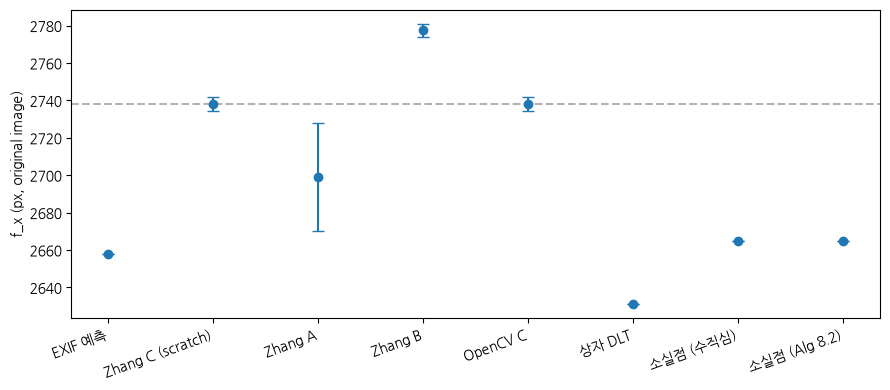

In [2]:
# 비교 기준: setC 원본 사진의 저장 픽셀 격자 (EXIF 자동 회전 없음).
det_compare = load_corners_checked('corners_setC.npz')
comparison_image = os.path.join(DATA, 'setC', det_compare['names'][0])
h_compare, w_compare = E.load_image(comparison_image, gray=True).shape[:2]
comparison_size = (w_compare, h_compare)
rows = []
def row(method, K, image_size, sigma=None, source=''):
    K = IO.rescale_K_for_image(K, image_size, comparison_size)
    sigma = None if sigma is None else float(sigma) * comparison_size[0] / image_size[0]
    rows.append(dict(method=method, f_x=K[0, 0], f_y=K[1, 1], sigma_f=(sigma if sigma is not None else float('nan')),
                     c_x=K[0, 2], c_y=K[1, 2], source=source + f' · 기준 {comparison_size[0]}×{comparison_size[1]} px'))
try:
    z = IO.load_json(IO.rpath('K_exif.json')); row('EXIF 예측', z['K'], z['image_size'], source='Part 1.1')
except FileNotFoundError: pass
for s, label in (('setC', 'Zhang C (scratch)'), ('setA', 'Zhang A'), ('setB', 'Zhang B')):
    try:
        z = IO.load_json(IO.rpath(f'zhang_{s}.json')); row(label, z['K'], z['image_size'], z['std']['fx'], 'Part 2 · RMS %.3f · %s' % (z['rms'], z.get('init', '')))
    except FileNotFoundError: pass
try:
    z = IO.load_json(IO.rpath('opencv_setC.json')); row('OpenCV C', z['K'], z['image_size'], z['std']['fx'], 'Part 2.7 · RMS %.3f' % z['rms'])
except FileNotFoundError: pass
try:
    z = IO.load_json(IO.rpath('dlt.json')); row('상자 DLT', z['K'], z['image_size'], source='Part 3 · %d점 · RMS %.2f' % (z['n_points'], z['rms']))
except FileNotFoundError: pass
try:
    z = IO.load_json(IO.rpath('vp.json'))
    row('소실점 (수직심)', G.make_K(z['f_mean'], z['f_mean'], z['pp'][0], z['pp'][1]), z['image_size'], source='Part 4.2')
    row('소실점 (Alg 8.2)', z['K_alg82'], z['image_size'], source='Part 4.2')
except FileNotFoundError: pass
assert rows, '결과 파일이 없습니다 — Part 1–4 를 먼저 실행하세요'
IO.write_f_table(rows)
IO.save_json(IO.rpath('f_table_context.json'), dict(image_size=list(comparison_size), image=os.path.relpath(comparison_image, DATA)))
ref = next((r for r in rows if r['method'].startswith('Zhang C')), rows[0])
print('모든 f · c · σ(f)는 원본 이미지 크기', comparison_size, '기준; 각 RMS는 해당 방법의 계산 해상도 기준입니다.')
print('%-18s %9s %9s %8s %8s %8s %8s  %s' % ('method', 'f_x', 'f_y', 'σ(f)', 'Δf(%)', 'c_x', 'c_y', 'source'))
for r in rows:
    print('%-18s %9.1f %9.1f %8s %8.2f %8.1f %8.1f  %s' % (r['method'], r['f_x'], r['f_y'], ('%.2f' % r['sigma_f']) if np.isfinite(r['sigma_f']) else '-', (r['f_x'] / ref['f_x'] - 1) * 100, r['c_x'], r['c_y'], r['source']))
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(range(len(rows)), [r['f_x'] for r in rows], yerr=[r['sigma_f'] if np.isfinite(r['sigma_f']) else 0 for r in rows], fmt='o', capsize=4)
ax.set_xticks(range(len(rows))); ax.set_xticklabels([r['method'] for r in rows], rotation=20, ha='right'); ax.set_ylabel('f_x (px, original image)'); ax.axhline(ref['f_x'], color='0.7', ls='--')
fig.tight_layout(); fig.savefig(IO.rpath('part6_f_table.png'), dpi=110)


**보고서 6.1** — 표 + 각 방법의 오차 원인(최소 한 줄씩): EXIF(환산 규약 · 센서 사용 영역), Zhang A(퇴화 · σ), B(가장자리 미관측), DLT(점 수 · 깊이 범위 · 클릭 오차), 소실점(직선 클릭 오차의 전파 · 직교 가정). **어느 값을 최종 K 로 쓰겠는가, 왜.**

## 6.2 함정 문항 (각 1점 — 본인 데이터의 숫자로 답할 것)
**(a)** 세트 A 로 얻은 f 를 믿을 수 있는가? RMS 와 σ(f) 를 세트 C 와 나란히 쓰고, Zhang §4 의 퇴화와 "재투영 오차의 함정" 으로 설명.

In [3]:
for s in ('setA', 'setC'):
    try:
        z = IO.load_json(IO.rpath(f'zhang_{s}.json')); print('%s: f = %.1f ± %.1f px (σ/f = %.2f %%), RMS %.3f px, k1 = %.4f ± %.4f, init = %s' % (s, z['K'][0][0], z['std']['fx'], z['std']['fx'] / z['K'][0][0] * 100, z['rms'], z['dist'][0], z['std']['k1'], z.get('init', '')))
    except FileNotFoundError:
        print(s, '결과 없음')

setA: f = 2699.1 ± 28.9 px (σ/f = 1.07 %), RMS 0.413 px, k1 = 0.0654 ± 0.0016, init = closed-form
setC: f = 2738.1 ± 3.8 px (σ/f = 0.14 %), RMS 1.277 px, k1 = 0.0710 ± 0.0019, init = closed-form


**(b)** 1/2 로 축소한 사진의 K 는? Part 1.3 의 예측과 재캘리브레이션 결과를 나란히 — 픽셀 중심(0.5 px) 규약이 만드는 차이(축소 0.25 px · 회전 1 px)를 실험으로 구분할 수 있는가 (σ(c) 와 비교).

In [4]:
try:
    t = IO.load_json(IO.rpath('K_transform_check.json'))
    for nm, v in t.items():
        Kp, Kr = np.array(v['K_pred']), np.array(v['K_recal'])
        print('%-10s 예측 f=(%.1f, %.1f) c=(%.2f, %.2f) | 재캘리브레이션 f=(%.1f, %.1f) c=(%.2f, %.2f) | Δc=(%.2f, %.2f)' % (nm, Kp[0,0], Kp[1,1], Kp[0,2], Kp[1,2], Kr[0,0], Kr[1,1], Kr[0,2], Kr[1,2], Kr[0,2]-Kp[0,2], Kr[1,2]-Kp[1,2]))
    print('σ(c) (Part 2):', IO.load_K('K.json')[1].get('std'))
except FileNotFoundError:
    print('Part 1.3 의 검증 셀을 Part 2 뒤에 실행하면 K_transform_check.json 이 생깁니다.')

1/2 축소     예측 f=(1369.1, 1369.5) c=(990.75, 735.25) | 재캘리브레이션 f=(1371.1, 1371.6) c=(990.62, 735.18) | Δc=(-0.13, -0.07)
90° 회전     예측 f=(2739.0, 2738.1) c=(1528.00, 1982.00) | 재캘리브레이션 f=(2739.0, 2738.1) c=(1528.00, 1982.00) | Δc=(0.00, 0.00)
σ(c) (Part 2): {'fx': 3.8394732622900354, 'fy': 3.9766063875178044, 'cx': 1.0953779113715088, 'cy': 1.1582535165989583}


**(c)** 보드 사진 한 장의 (R, t) 에서 카메라의 위치 C 를 구해, 보드 평면에서 렌즈까지의 수직 거리와 줄자 실측을 비교. `t`, `−t` 를 쓰면 어떤 숫자가 나오는지도 함께.

In [5]:
# ==============================================================================
# TODO  camera_position_from_pose
# 참조: MVG §6.1 (P = K[R|t], X_c = R X_w + t), §6.2.1 (카메라 중심 PC = 0)
# 카메라 중심은 X_c = 0 인 월드 점: 0 = R C + t → C = −Rᵀ t.   t 도, −t 도 아님 (t 는 월드 원점의 카메라 좌표)
# 보드를 월드로 쓰면 C 의 z 성분의 절댓값 = 보드 평면에서 렌즈까지의 수직 거리 → 줄자와 비교 (Part 6 함정 (c))
# ==============================================================================
def camera_position_from_pose(R, t):
    """X_c = R X_w + t 에서 카메라 중심의 월드(보드) 좌표: C = −Rᵀ t  (MVG §6.1 · §6.2.1 PC = 0).
    ※ t 는 '월드 원점의 카메라 좌표' 이지 카메라 위치가 아님. −t 도 아님 (회전을 거꾸로 풀어야 함)."""
    # ---- 여기에 작성 ----
    R = np.asarray(R, float)
    return -R.T @ np.ravel(np.asarray(t, float))          # 0 = R C + t → C = −Rᵀ t


In [6]:
import cv2
meas = IO.load_json(IO.rpath('measurements.json')); det = load_corners_checked('corners_setC.npz')
K_z, kinfo = IO.load_K('K.json'); dist_z, _ = IO.load_dist('dist.json')
K_z = IO.rescale_K_for_image(K_z, kinfo['image_size'], det['image_size'])
name = meas['camera_height_image']
if name not in det['names']:
    raise ValueError(f'실측 사진 {name!r}의 코너가 없습니다. 파일명과 Part 0 검출 실패 목록을 확인하세요.')
i = det['names'].index(name)
X, m = det['objpoints'][i], det['imgpoints'][i]
ok, rvec, tvec = cv2.solvePnP(X, m, K_z, dist_z)        # (R, t) 는 Part 2 의 extrinsics 또는 solvePnP (여기서는 허용 — 질문의 초점은 C)
if not ok:
    raise RuntimeError(f'{name}: solvePnP가 자세를 구하지 못했습니다.')
R = G.rodrigues(rvec.ravel()); t = tvec.ravel()
C = camera_position_from_pose(R, t)
h_meas = meas.get('camera_height_mm')
print('사진 %s: t = %s,  −t = %s' % (det['names'][i], t.round(1), (-t).round(1)))
print('카메라 중심 C = −Rᵀt = %s → 보드 평면까지 수직 거리 |C_z| = %.1f mm' % (C.round(1), abs(C[2])) + (',  실측 %.1f mm (오차 %+.1f %%)' % (h_meas, (abs(C[2]) / h_meas - 1) * 100) if h_meas else ''))
print('|t| = %.1f (보드 원점까지 거리), t_z = %.1f (보드 원점의 깊이) — 둘 다 "높이" 가 아님' % (np.linalg.norm(t), t[2]))
IO.save_json(IO.rpath('part6_camera_position.json'), dict(image=det['names'][i], R=R, t=t, C=C, height_est=abs(C[2]), height_measured=h_meas))

사진 KakaoTalk_Photo_2026-11-09-14-12-13.jpeg: t = [-126.6 -177.2  516.6],  −t = [ 126.6  177.2 -516.6]
카메라 중심 C = −Rᵀt = [ 118.6  115.1 -535.7] → 보드 평면까지 수직 거리 |C_z| = 535.7 mm,  실측 500.0 mm (오차 +7.1 %)
|t| = 560.6 (보드 원점까지 거리), t_z = 516.6 (보드 원점의 깊이) — 둘 다 "높이" 가 아님


'/home/shw/3dvision/results/part6_camera_position.json'

**(d)** 왜곡을 무시하고(k = 0 고정) 캘리브레이션한 f, 왜곡을 함께 추정한 f, 보정한 영상으로 다시 캘리브레이션한 f — 세 값이 왜 다른지 (MVG Table 7.3 의 "fy 1673 → 1580" 과 연결).

In [7]:
import cv2
objs = [o.astype(np.float32) for o in det['objpoints']]; imgs = [mm.astype(np.float32).reshape(-1, 1, 2) for mm in det['imgpoints']]
W, H = det['image_size']
base = cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST
r0, K0_, d0_, *_ = cv2.calibrateCamera(objs, imgs, (W, H), None, None, flags=base | cv2.CALIB_FIX_K1 | cv2.CALIB_FIX_K2)
r1, K1_, d1_, *_ = cv2.calibrateCamera(objs, imgs, (W, H), None, None, flags=base)
objs2, imgs2 = [], []
for nm in det['names']:
    g = E.load_image(os.path.join(DATA, 'setC', nm), gray=True, scale=det['scale'])
    g = cv2.undistort(g, np.array(K1_), np.array(d1_))
    ok, c = Bd.detect_corners(g, det['pattern'])
    if ok: objs2.append(objs[0]); imgs2.append(c.astype(np.float32).reshape(-1, 1, 2))
r2, K2_, d2_, *_ = cv2.calibrateCamera(objs2, imgs2, (W, H), None, None, flags=base | cv2.CALIB_FIX_K1 | cv2.CALIB_FIX_K2)
print('k 고정 0 (원본):        f = %.1f / %.1f, RMS %.3f' % (K0_[0,0], K0_[1,1], r0))
print('k 추정 (원본):          f = %.1f / %.1f, RMS %.3f, k1 = %.4f' % (K1_[0,0], K1_[1,1], r1, d1_.ravel()[0]))
print('k 고정 0 (보정 영상):   f = %.1f / %.1f, RMS %.3f  (%d장)' % (K2_[0,0], K2_[1,1], r2, len(imgs2)))
IO.save_json(IO.rpath('part6_f_distortion.json'), dict(f_k0=[K0_[0,0], K0_[1,1]], rms_k0=r0, f_k=[K1_[0,0], K1_[1,1]], rms_k=r1, f_undist=[K2_[0,0], K2_[1,1]], rms_undist=r2))

k 고정 0 (원본):        f = 2660.8 / 2657.2, RMS 1.894
k 추정 (원본):          f = 2738.1 / 2739.0, RMS 1.277, k1 = 0.0710
k 고정 0 (보정 영상):   f = 2737.8 / 2738.6, RMS 1.259  (15장)


'/home/shw/3dvision/results/part6_f_distortion.json'

**(e)** 보드 한 행의 등간격 코너 **세 개** 만으로 교비로 소실점을 예측하고(MVG §2.5 교비 · §2.7.2 길이비로 소실점), 그 행 전체(nx 개) · 모든 행으로 구한 "실제" 소실점과 비교. 코너 오차 0.3 px 가 소실점을 얼마나 흔드는가.

In [8]:
# ==============================================================================
# TODO  cross_ratio_vp
# 참조: MVG §2.5 교비(cross ratio) — P¹ 의 기본 불변량, §2.7.2 길이비로 소실점 구하기
# 등간격 세 점의 월드 좌표를 0, 1, 2, 소실점 = ∞ 로 두면 교비 {0, 1; 2, ∞} = (2·∞)/(1·∞) = 2
# 이미지의 직선 위 1D 좌표 a = 0 (p1), b (p2), c (p3), x (v) 로 같은 교비:  (c − a)(x − b) / ((c − b)(x − a)) = 2  → x 에 대해 풀기
# 1D 좌표는 p1 에서 p3 방향 단위벡터 e 에 대한 투영.  반환: 소실점 픽셀 (2,) = p1 + x e
# 함정: 세 점 간격 1 px 오차가 소실점 위치를 수십 px 흔듦 — Part 6 (e) 에서 모든 코너로 구한 소실점과 비교
# ==============================================================================
def cross_ratio_vp(p1, p2, p3, p4_world_ratio=None):
    """등간격 세 점 p1, p2, p3 (이미지, 같은 직선) 에서 소실점 예측 (MVG §2.5 교비, §2.7.2 길이비로 소실점):
    교비 Cr(p1, p2; p3, v) = Cr(0, 1; 2, ∞) = ... 등간격이면  (p1 p3 · p2 v)/(p2 p3 · p1 v) = 2 → v 를 풀어 직선 위 1D 좌표로."""
    # ---- 여기에 작성 ----
    # p4_world_ratio: 세 점의 월드 교비 값 Cr = (X3 − X1)/(X3 − X2).  None 이면 등간격 (0, 1, 2) → 2
    p1, p2, p3 = (np.asarray(p, float).ravel()[:2] for p in (p1, p2, p3))
    rho = 2.0 if p4_world_ratio is None else float(p4_world_ratio)
    e = (p3 - p1) / np.linalg.norm(p3 - p1)               # 직선 방향 단위벡터 (p1 → p3)
    b, c = (p2 - p1) @ e, (p3 - p1) @ e                   # 1D 좌표 (a = 0)
    # (c − a)(x − b) / ((c − b)(x − a)) = ρ  →  x = c b / (c − ρ (c − b))
    den = c - rho * (c - b)
    x = c * b / den if abs(den) > 1e-12 else np.inf       # den = 0 이면 이미지에서도 등간격 → 무한원점
    return p1 + x * e


In [9]:
import cv2
def undist(uv): return cv2.undistortPoints(np.asarray(uv, float).reshape(-1, 1, 2), K_z, dist_z, P=K_z).reshape(-1, 2)
nx, ny = det['pattern']
errs3, errs_wide = [], []
for i in range(len(det['names'])):
    c = undist(det['imgpoints'][i]).reshape(ny, nx, 2)
    rows_lines = np.array([G.line_through(c[r, 0], c[r, -1]) for r in range(ny)])
    rows_lines /= np.linalg.norm(rows_lines[:, :2], axis=1, keepdims=True)
    _, _, Vt = np.linalg.svd(rows_lines); v_true = G.hnorm(Vt[-1])[:2]
    for r in range(ny):
        v3 = cross_ratio_vp(c[r, 0], c[r, 1], c[r, 2]); errs3.append(np.linalg.norm(v3 - v_true))                           # 인접 3점
        vw = cross_ratio_vp(c[r, 0], c[r, (nx - 1) // 2], c[r, nx - 1]); errs_wide.append(np.linalg.norm(vw - v_true))     # 양 끝 + 가운데 (9개 행이면 0, 4, 8)
errs3, errs_wide = np.array(errs3), np.array(errs_wide)
print('교비 예측 소실점의 오차 (px): 인접 3점 — 중앙값 %.0f, 90%% %.0f;  넓은 간격(양 끝 + 가운데) — 중앙값 %.0f, 90%% %.0f' % (np.median(errs3), np.percentile(errs3, 90), np.median(errs_wide), np.percentile(errs_wide, 90)))
print('소실점까지의 거리(참고, 중앙값): %.0f px' % np.median([np.linalg.norm(G.hnorm(np.linalg.svd(np.array([G.line_through(undist(det['imgpoints'][i]).reshape(ny, nx, 2)[r, 0], undist(det['imgpoints'][i]).reshape(ny, nx, 2)[r, -1]) for r in range(ny)]))[2][-1])[:2] - np.array(det['image_size']) / 2) for i in range(len(det['names']))]))
IO.save_json(IO.rpath('part6_cross_ratio.json'), dict(median_err_adjacent=float(np.median(errs3)), median_err_wide=float(np.median(errs_wide)), p90_adjacent=float(np.percentile(errs3, 90))))

교비 예측 소실점의 오차 (px): 인접 3점 — 중앙값 1184, 90% 190132;  넓은 간격(양 끝 + 가운데) — 중앙값 99, 90% 15781
소실점까지의 거리(참고, 중앙값): 12885 px


'/home/shw/3dvision/results/part6_cross_ratio.json'

## 6.3 LLM 풀이 감정 (3점)
아래는 LLM 이 작성한 "풀이" 두 편입니다. 각 풀이에서 **틀린 곳을 모두 찾아** 무엇이 왜 틀렸는지, 맞는 식은 무엇인지 보고서에 쓰세요 (강의 · 교재의 어느 결과가 근거인지 달면 가산).

---
**풀이 A — "체커보드 사진 한 장에서 카메라 위치 구하기"**

> `cv2.solvePnP` 로 얻은 `rvec`, `tvec` 에서 `R = cv2.Rodrigues(rvec)` 이고, 카메라의 위치는 보드 좌표계에서 `tvec` 입니다. 따라서 보드 평면으로부터 카메라까지의 높이는 `tvec[2]` 입니다.
> 제 데이터에서 `tvec = [−31.2, 118.5, 547.3]` 이므로 카메라는 보드 위 547.3 mm 높이에 있고, 보드 원점에서 x 로 −31 mm, y 로 119 mm 옆입니다.
> 참고로 OpenCV 의 왜곡 계수는 픽셀 좌표에 적용되므로, 보드 코너 픽셀 좌표 (u, v) 에 대해 r² = u² + v² 를 계산해 u(1 + k₁r² + k₂r⁴) 로 보정한 뒤 solvePnP 에 넣었습니다.

---
**풀이 B — "f 를 믿을 수 있는지"**

> 세트 A(정면 평행 15장)로 `calibrateCamera` 를 돌리니 RMS 가 0.21 px 로 세트 C 의 0.34 px 보다 낮았습니다. 재투영 오차가 더 작으므로 세트 A 의 f = 3312 px 가 세트 C 의 f = 2980 px 보다 정확합니다.
> 정면 평행 사진은 보드 전체가 선명하고 코너 검출이 정확해서, 15장만으로도 f 와 주점이 안정적으로 결정됩니다. 더 확실히 하려면 같은 방식으로 30장을 더 찍어 추가하면 됩니다.
> 이미지를 1/2 로 줄여 쓰려면 K 의 모든 원소를 2 로 나누면 되고, 왜곡 계수도 2 로 나눕니다.

---

## 보너스 (5점) — RAW vs JPEG (9월 HW1 Part E)
같은 장면을 RAW(DNG) 와 JPEG 로 함께 찍을 수 있는 폰이면: (i) 평탄한 벽을 같은 설정으로 10장 연속 촬영 → 픽셀별 평균 · 분산 → 평균–분산 곡선(Photon Transfer Curve).
RAW 는 직선(σ² = aI + b), JPEG 는 감마 · 노이즈 제거 때문에 휨. (ii) 또는 RAW 를 직접 현상(디모자이킹 · 감마)한 보드 사진 세트와 JPEG 세트의 σ(f) · 코너 잔차 비교.
`data/noise/jpeg/*.jpg`, `data/noise/raw/*.dng` (rawpy 필요). 없으면 생략.

In [10]:
nz = os.path.join(DATA, 'noise')
if os.path.isdir(nz):
    def mean_var_curve(stack, nbins=30):
        mu, var = stack.mean(axis=0), stack.var(axis=0, ddof=1)
        bins = np.quantile(mu, np.linspace(0, 1, nbins + 1)); out = []
        for a, b in zip(bins[:-1], bins[1:]):
            sel = (mu >= a) & (mu < b)
            if sel.sum() > 100: out.append((mu[sel].mean(), var[sel].mean()))
        return np.array(out)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    jp = E.list_images(os.path.join(nz, 'jpeg'))
    if jp:
        st = np.stack([E.load_image(p, gray=True).astype(float) for p in jp]); cv_ = mean_var_curve(st); ax.plot(cv_[:, 0], cv_[:, 1], 'o-', label='JPEG (gray)')
    try:
        import rawpy
        dn = sorted(glob.glob(os.path.join(nz, 'raw', '*.dng')) + glob.glob(os.path.join(nz, 'raw', '*.DNG')))
        if dn:
            st = np.stack([rawpy.imread(p).raw_image_visible.astype(float)[0::2, 0::2] for p in dn]); cv_ = mean_var_curve(st); ax.plot(cv_[:, 0], cv_[:, 1], 's-', label='RAW (R channel, 12/14-bit)')
    except ImportError:
        print('rawpy 없음 — pip install rawpy')
    ax.set_xlabel('mean'); ax.set_ylabel('variance'); ax.legend(); fig.savefig(IO.rpath('bonus_mean_variance.png'), dpi=110)
else:
    print('data/noise 없음 — 보너스 생략')

data/noise 없음 — 보너스 생략


## 보고서에 넣을 것 (Part 6, 슬라이드 4장) + 전체 상한 30장
1. f 비교표 + 그림 + 최종 K 선택과 근거
2. 함정 (a)–(c) 답 (숫자 포함)
3. 함정 (d)–(e) 답 (숫자 포함)
4. LLM 풀이 감정 — 풀이 A · B 의 오류 목록(오류 → 근거(강의 · 교재) → 바른 식)

In [11]:
CK.run_all(globals());